# California Housing Price Prediction: End-to-End Machine Learning Project

This project follows the end-to-end machine learning workflow to predict median house values in California districts using data from the 1990 California census.

### Machine Learning Workflow Stages:
1. **Frame the Problem and Look at the Big Picture**
2. **Get the Data**
3. **Discover and Visualize the Data to Gain Insights**
4. **Prepare the Data for Machine Learning Algorithms**
5. **Select and Train Models**
6. **Fine-Tune the Model**
7. **Evaluate the Solution on the Test Set**
8. **Launch, Monitor, and Maintain the System**

In [1]:
# Standard scientific and data manipulation libraries
from pathlib import Path
import tarfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure reproducible random output across runs
np.random.seed(42)

# Configure Matplotlib styling for high-quality figures
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

# Directory path for saving plots and figures
IMAGES_PATH = Path("images") / "end_to_end_project"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## 1. Get the Data

We define a function `load_housing_data()` that downloads the compressed archive, extracts `housing.csv`, and returns it as a pandas DataFrame.

In [2]:
def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as housing_tarball:
        housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Preliminary Data Inspection
- Check column names, non-null counts, and data types with `info()`.
- Inspect unique categories for categorical features with `value_counts()`.
- View summary statistics of numerical attributes using `describe()`.

In [3]:
# Quick description of the data: column types, memory usage, and non-null counts
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
# Categories present in the ocean_proximity attribute
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [5]:
# Summary statistics for numerical attributes
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


### Visualizing Feature Distributions via Histograms
Key observations from the histograms below:
1. **Median Income**: Scaled and pre-processed (expressed in tens of thousands of USD, capped at 15 for higher incomes and 0.5 for lower incomes).
2. **Housing Median Age & Median House Value**: Both attributes are capped at their upper bounds (house value capped at $500,000).
3. **Heavy Tails**: Several histograms are tail-heavy, extending much farther to the right than the left. This will require transformation to bell-shaped distributions for certain ML algorithms.

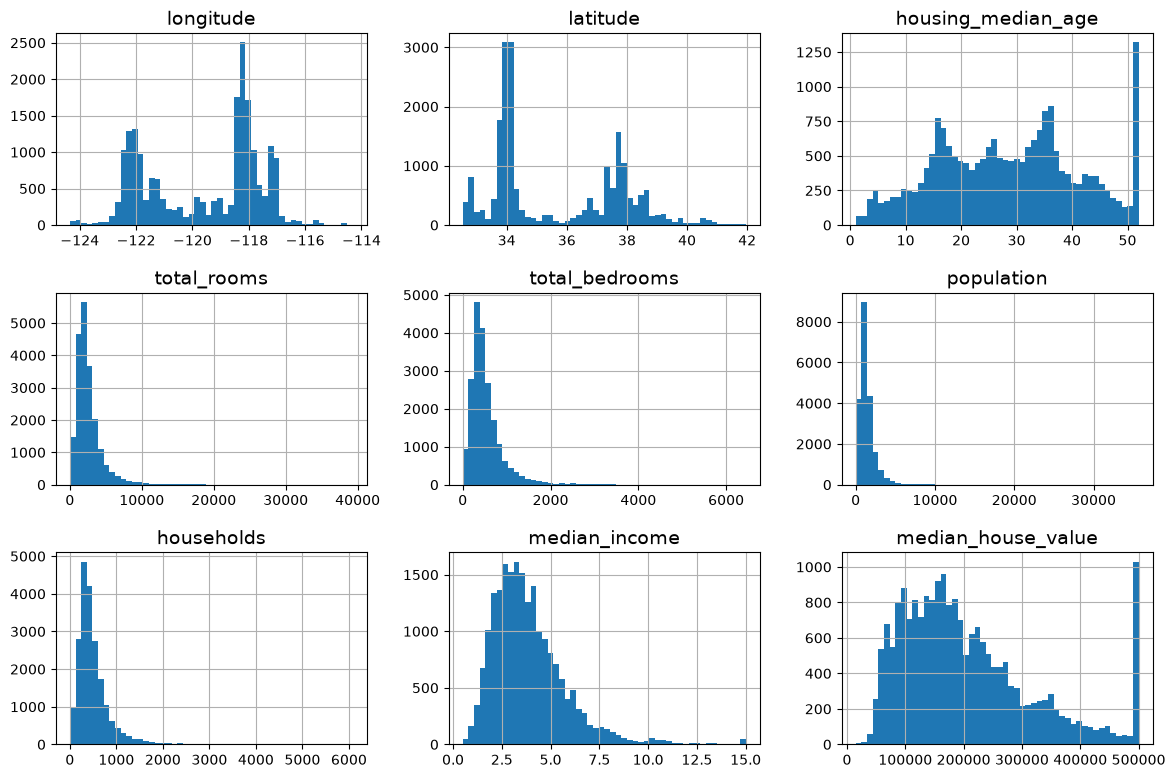

In [6]:
# Plotting numerical attribute distribution histograms
housing.hist(bins=50, figsize=(12, 8))
save_fig("attribute_histogram_plots")
plt.show()

## 2. Create a Test Set

Setting aside a test set early prevents **Data Snooping Bias**, where patterns observed in the test data inadvertently influence model selection.

### Splitting Considerations:
1. **Random Permutation Splitting**: Shuffling row indices.
2. **Stable Identifier Splitting**: Using hash functions (e.g., CRC32) on permanent IDs to guarantee consistent splits even when new rows are added.
3. **Stratified Sampling**: Ensuring that critical subgroup proportions (such as median income brackets) are preserved across both train and test partitions.

In [7]:
def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

train_set, test_set = shuffle_and_split_data(housing, 0.2)
print(f"Training set size: {len(train_set)}, Test set size: {len(test_set)}")

Training set size: 16512, Test set size: 4128


### Stable Identifier Splitting via CRC32
To keep the test set consistent across multiple executions even when updating the dataset, we can use row hashes.

In [8]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

housing_with_id = housing.reset_index()
train_set_id, test_set_id = split_data_with_id_hash(housing_with_id, 0.2, "index")
print(f"Hash split train size: {len(train_set_id)}, test size: {len(test_set_id)}")

Hash split train size: 16512, test size: 4128


In [9]:
# Standard Scikit-Learn random split
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)
print(f"train_test_split test size: {len(test_set)}")
print("Missing bedrooms in test set:", test_set["total_bedrooms"].isnull().sum())

train_test_split test size: 4128
Missing bedrooms in test set: 44


### Random Sampling Risk & Binomial Distribution Analysis
Purely random sampling carries the risk of introducing significant sampling bias when sample size is limited or subsets are critical.

For instance, consider a population with $51.1\%$ females. If we draw a random sample of $n = 1,000$ individuals, the probability of drawing a skewed sample ($< 48.5\%$ or $> 53.5\%$) can be quantified using the cumulative distribution function (CDF) of the binomial distribution:
$$\mu = n \cdot p = 1000 \times 0.511 = 511$$
$$\sigma = \sqrt{n \cdot p \cdot (1 - p)} = \sqrt{1000 \times 0.511 \times 0.489} \approx 15.81$$